# P6 – Neural Network & Model Arena

## What this part does

This notebook owns two things. First, the **neural network** (a multi-layer perceptron, MLP): one flexible kind of model that we train for all three supervised tasks: genre, hit and happiness (valence). Second, the **Model Arena**: the final scoreboard that compares *every* model in the project fairly (same test set, same metrics) and says which won and whether the win is real.

In the app this gives two views: **Song Lab** (move sliders for energy, tempo, etc. and watch the network's genre guess change live) and **Model Arena** (a leaderboard per task; pick a model to see its scores and confusion matrix). The questions: *how does the network work, which model won each task, and why?*

## Concepts in plain English

**Neurons and layers.** A neuron takes a weighted sum of its inputs plus a bias, then applies an **activation function**. An MLP stacks layers of neurons: the **input layer** (our features) → one or two **hidden layers** → an **output layer**. Without activation functions, stacking layers would just give another weighted sum: a deep network would be no more powerful than linear regression. The activations add the bends that let the network draw curved boundaries.

**Activations.**
- **ReLU** (hidden layers): max(0, x). Passes positive values, blocks negative ones; simple and trains well.
- **Softmax** (output, genre): turns 6 scores into 6 probabilities that sum to 1.
- **Sigmoid** (output, hit): squashes one score into a probability between 0 and 1.
- **Identity/linear** (output, valence): just outputs the number.

**Training: forward pass, loss, backpropagation, gradient descent.** A **forward pass** pushes a batch of songs through the network to get predictions. A **loss** measures how wrong they are: cross-entropy for genre/hit, squared error for valence. **Backpropagation** uses the chain rule of calculus to work out, layer by layer from the output backwards, how much each weight contributed to the loss (its gradient). An optimiser (**Adam**, a smarter version of gradient descent) then nudges every weight a little in the direction that reduces the loss. The **learning rate** sets the step size; one pass over all training songs is an **epoch**; training repeats for many epochs.

**Overfitting in networks.** A network with enough neurons can memorise the training songs. We watch **training vs validation loss**: when validation loss stops improving while training loss keeps falling, the network is starting to overfit. **Early stopping** halts training at that point; **alpha** is an L2 weight penalty (like Ridge); and the number of hidden neurons, alpha and the learning rate are tuned by **cross-validation**.

**Fair comparison.** Every model in the project uses the **same train/test split** and the **same metric code** (`src/evaluate.py`), and was tuned with cross-validation on the training set only. But one test score can still be luck: with 854 test songs, a 1-point accuracy gap is only ~9 songs. The **bootstrap** resamples the test set with replacement 1,000 times and recomputes the score each time; the middle 95% of those scores is a **95% confidence interval**. If two models' intervals (or the interval of their difference) clearly overlap zero, we can't call a winner.

## Setup

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.model_selection import GridSearchCV, StratifiedKFold, KFold, train_test_split, cross_val_score
from sklearn.metrics import log_loss, accuracy_score, roc_auc_score, r2_score
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning

from src import data, evaluate
from src.style import GENRE_COLORS, PALETTE, setup_notebook_style

np.random.seed(42)
setup_notebook_style()
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 170, "display.max_colwidth", 50, "display.precision", 3)
FIG = data.ROOT / "results" / "figures" / "p6_arena"
MODELS = data.ROOT / "models" / "p6_neural"
FIG.mkdir(parents=True, exist_ok=True); MODELS.mkdir(parents=True, exist_ok=True)

X_train, X_test, y_train, y_test, feature_names = data.load_splits()
GENRES = data.GENRES
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (3413, 26)  Test: (854, 26)


## 1. The network, as a picture
Our genre network (the sizes below are the ones cross-validation picks in section 2): 26 input features → hidden layer(s) of ReLU neurons → 6 softmax outputs, one per genre. Every arrow is a weight that training adjusts.

In [2]:
def draw_network(layers, labels, title):
    fig, ax = plt.subplots(figsize=(10, 4.5)); ax.axis("off")
    shown = [min(n, 10) for n in layers]
    xs = np.linspace(0, 1, len(layers))
    pos = [[(x, y) for y in np.linspace(0.9, 0.1, s)] for x, s in zip(xs, shown)]
    for a, b in zip(pos[:-1], pos[1:]):
        for p in a:
            for q in b: ax.plot([p[0], q[0]], [p[1], q[1]], color="#bbbbbb", lw=0.4, zorder=1)
    colors = ["#3987e5"] + ["#8e6cd8"] * (len(layers) - 2) + ["#199e70"]
    for layer, c, n, lab, x in zip(pos, colors, layers, labels, xs):
        for p in layer: ax.scatter(*p, s=180, color=c, zorder=2, edgecolors="white")
        ax.text(x, 0.0, f"{lab}\n({n} neurons{', 10 shown' if n > 10 else ''})", ha="center", va="top", fontsize=10)
    ax.set_title(title); ax.set_ylim(-0.15, 1)
    return fig

## 2. Genre network: tune hidden layers, alpha and learning rate with cross-validation
Grid: 5 architectures × 4 alphas × 2 learning rates = 40 combinations, 5-fold stratified CV on the training set (macro F1). Every network uses **early stopping** (10% of its training data is held back to watch validation performance).

In [3]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
grid_params = {"hidden_layer_sizes": [(16,), (32,), (64,), (32, 16), (64, 32)],
               "alpha": [1e-4, 1e-3, 1e-2, 1e-1], "learning_rate_init": [1e-3, 1e-2]}
base_mlp = dict(activation="relu", solver="adam", early_stopping=True, max_iter=1000, n_iter_no_change=20, random_state=42)
g_genre = GridSearchCV(MLPClassifier(**base_mlp), grid_params, cv=cv, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train["genre"])
mlp_genre = g_genre.best_estimator_
print("Best:", g_genre.best_params_, " CV macro F1 = %.3f" % g_genre.best_score_)
res = pd.DataFrame(g_genre.cv_results_)
res["hidden"] = res.param_hidden_layer_sizes.astype(str)
res.pivot_table(index="hidden", columns="param_alpha", values="mean_test_score", aggfunc="max").round(3)

Best: {'alpha': 0.01, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.01}  CV macro F1 = 0.683


param_alpha,1.000e-04,1.000e-03,1.000e-02,1.000e-01
hidden,,,,
"(16,)",0.672,0.675,0.671,0.672
"(32, 16)",0.658,0.662,0.667,0.660
"(32,)",0.670,0.674,0.674,0.671
"(64, 32)",0.678,0.674,0.676,0.678
"(64,)",0.682,0.681,0.683,0.678


This shows that the network is **not very sensitive to its settings**: every combination scores between 0.66 and 0.68 macro F1. One hidden layer of **64 neurons** is slightly best; the two-layer networks are not better (our 26 features don't need a deep model). CV picked **64 neurons, alpha = 0.01, learning rate 0.01**.

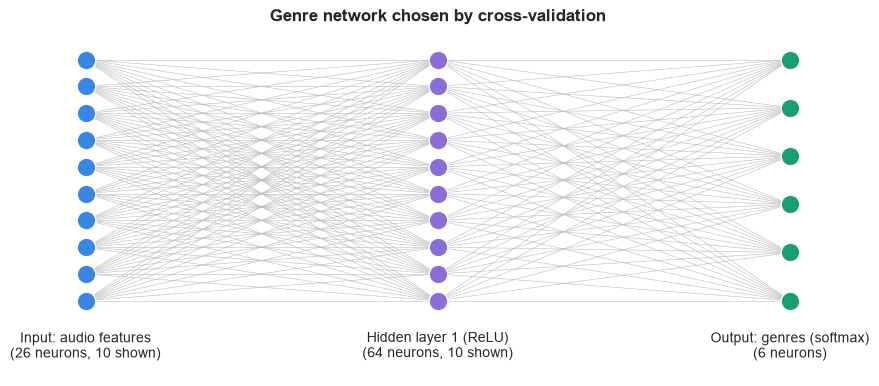

In [4]:
hs = list(g_genre.best_params_["hidden_layer_sizes"])
draw_network([len(feature_names)] + hs + [len(GENRES)], ["Input: audio features"] + [f"Hidden layer {i+1} (ReLU)" for i in range(len(hs))] + ["Output: genres (softmax)"],
             "Genre network chosen by cross-validation")
plt.savefig(FIG / "network_diagram.png", dpi=120, bbox_inches="tight"); plt.show()

In [5]:
pred = mlp_genre.predict(X_test)
met = evaluate.classification_metrics(y_test["genre"], pred)
evaluate.log_score("P6 Neural Network", "MLP (neural network)", "genre", met)
evaluate.save_predictions("genre", "MLP (neural network)", X_test.index, pred, y_true=y_test["genre"])
print("Genre MLP test: accuracy %.3f, macro F1 %.3f   (stopped after %d epochs)" % (met["accuracy"], met["macro_f1"], mlp_genre.n_iter_))

Genre MLP test: accuracy 0.728, macro F1 0.693   (stopped after 35 epochs)


## 3. Training vs validation loss
To see overfitting, we train the chosen genre network epoch by epoch on 90% of the training songs and measure the cross-entropy loss on both the 90% (training) and the held-back 10% (validation) after every epoch, without early stopping, for 300 epochs.

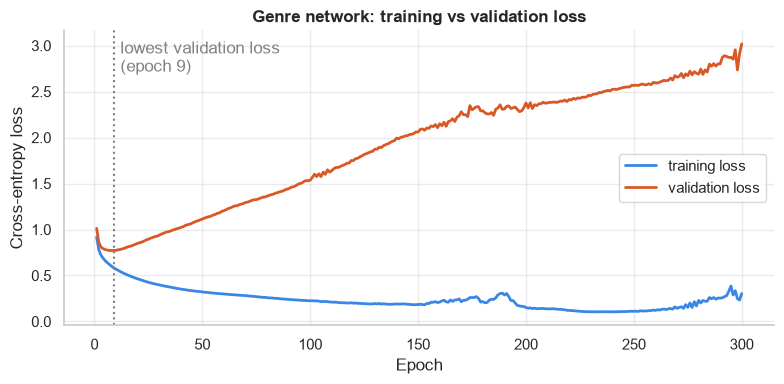

At epoch 9: train loss 0.583, val loss 0.772
At epoch 300: train loss 0.304, val loss 3.019


In [6]:
Xa, Xv, ya, yv = train_test_split(X_train, y_train["genre"], test_size=0.1, stratify=y_train["genre"], random_state=42)
net = MLPClassifier(hidden_layer_sizes=g_genre.best_params_["hidden_layer_sizes"], alpha=g_genre.best_params_["alpha"],
                    learning_rate_init=g_genre.best_params_["learning_rate_init"], random_state=42)
train_loss, val_loss = [], []
for epoch in range(300):
    net.partial_fit(Xa, ya, classes=np.array(GENRES))
    train_loss.append(log_loss(ya, net.predict_proba(Xa), labels=net.classes_))
    val_loss.append(log_loss(yv, net.predict_proba(Xv), labels=net.classes_))
best_epoch = int(np.argmin(val_loss)) + 1
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, 301), train_loss, color="#3987e5", lw=2, label="training loss")
ax.plot(range(1, 301), val_loss, color="#d95926", lw=2, label="validation loss")
ax.axvline(best_epoch, color="gray", ls=":"); ax.text(best_epoch + 3, max(val_loss) * 0.9, f"lowest validation loss\n(epoch {best_epoch})", color="gray")
ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy loss"); ax.set_title("Genre network: training vs validation loss"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "loss_curve.png", dpi=120); plt.show()
print(f"At epoch {best_epoch}: train loss {train_loss[best_epoch-1]:.3f}, val loss {val_loss[best_epoch-1]:.3f}")
print(f"At epoch 300: train loss {train_loss[-1]:.3f}, val loss {val_loss[-1]:.3f}")

This shows textbook overfitting. Both losses fall at first; the **validation loss is lowest around epoch 9** (0.77) and then climbs steeply (to 3.0 by epoch 300) while the training loss keeps falling (to 0.30): the network is memorising the training songs instead of learning general patterns. That is exactly why we use **early stopping**: the tuned network stopped automatically after 35 epochs (it waits 20 epochs without improvement before stopping), long before the damage at epoch 300.

## 4. Hit network (sigmoid output)
`MLPClassifier` has no `class_weight`, so we pass **balanced sample weights** (each hit counts ~10× more). Tuned by 5-fold CV on ROC-AUC.

In [7]:
sw = compute_sample_weight("balanced", y_train["hit"])
g_hit = GridSearchCV(MLPClassifier(**base_mlp), grid_params, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train["hit"], sample_weight=sw)
mlp_hit = g_hit.best_estimator_
p_hit = mlp_hit.predict_proba(X_test)[:, 1]
met = evaluate.classification_metrics(y_test["hit"], (p_hit >= 0.5).astype(int), p_hit)
evaluate.log_score("P6 Neural Network", "MLP (neural network)", "hit", met)
evaluate.save_predictions("hit", "MLP (neural network)", X_test.index, (p_hit >= 0.5).astype(int), p_hit, y_true=y_test["hit"])
print("Best:", g_hit.best_params_, " CV ROC-AUC = %.3f" % g_hit.best_score_)
pd.Series(met).round(3)

Best: {'alpha': 0.1, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.01}  CV ROC-AUC = 0.765


accuracy     0.734
macro_f1     0.537
precision    0.151
recall       0.538
f1           0.236
roc_auc      0.723
dtype: float64

## 5. Happiness network (linear output, valence removed from inputs)

In [8]:
Xtr_v, Xte_v = X_train.drop(columns="valence"), X_test.drop(columns="valence")
g_val = GridSearchCV(MLPRegressor(**base_mlp), grid_params, cv=KFold(5, shuffle=True, random_state=42), scoring="r2", n_jobs=-1).fit(Xtr_v, y_train["valence"])
mlp_val = g_val.best_estimator_
p_val = mlp_val.predict(Xte_v)
met = evaluate.regression_metrics(y_test["valence"], p_val)
evaluate.log_score("P6 Neural Network", "MLP (neural network)", "valence", met)
evaluate.save_predictions("valence", "MLP (neural network)", X_test.index, p_val, y_true=y_test["valence"])
print("Best:", g_val.best_params_, " CV R² = %.3f" % g_val.best_score_)
pd.Series(met).round(3)

Best: {'alpha': 0.1, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.01}  CV R² = 0.315


rmse    0.184
mae     0.147
r2      0.322
dtype: float64

This shows the network is competitive on every task but not dominant: for **genre** it reaches **72.8% accuracy** (macro F1 0.693), for **valence R² = 0.322** (the best of all models, a little above the linear models' 0.295, since it can capture some non-linear effects), and for **hit** a ROC-AUC of 0.723, below the tree ensembles. With balanced weights and a 0.5 threshold it catches 54% of hits but with low precision (15%).

## 6. The Model Arena
Every model's test scores, read from the shared `results/scores.csv`. One table per task; the best value in each column is **bold-highlighted**. The "baseline" rows are dummy models (random guessing or always predicting the mean); anything useful must beat them.

In [9]:
scores = evaluate.load_scores()
TASKS = {"genre": (["accuracy", "macro_f1"], "accuracy"),
         "hit": (["roc_auc", "f1", "precision", "recall", "accuracy"], "roc_auc"),
         "valence": (["r2", "rmse", "mae"], "r2")}
LOWER_BETTER = {"rmse", "mae"}

def arena_table(task):
    cols, key = TASKS[task]
    t = scores[scores.task == task][["component", "model"] + cols].sort_values(key, ascending=False).reset_index(drop=True)
    t.index = t.index + 1
    return t

def show_arena(task):
    cols, key = TASKS[task]
    t = arena_table(task)
    def bold(col):
        best = col.min() if col.name in LOWER_BETTER else col.max()
        return ["font-weight: bold; background-color: #d7f0e3" if v == best else "" for v in col]
    return t.style.apply(bold, subset=cols).format({c: "{:.3f}" for c in cols})

show_arena("genre")

,component,model,accuracy,macro_f1
1,P6 Neural Network,MLP (neural network),0.728,0.693
2,P4 Similar Songs,SVM (linear),0.725,0.697
3,P3 Genre Detector,Logistic regression,0.715,0.685
4,P4 Similar Songs,SVM (RBF),0.714,0.684
5,P4 Similar Songs,kNN classifier (k=13),0.701,0.671
6,P3 Genre Detector,Gaussian Naive Bayes,0.649,0.609
7,baseline,Dummy (uniform guess),0.180,0.178


This shows a very tight race for genre: the **MLP (72.8%)**, **linear SVM (72.5%)**, logistic regression (71.5%), RBF SVM (71.4%) and kNN (70.1%) are all within 3 points; only Naive Bayes (64.9%) is clearly behind, held back by its wrong independence assumption. All are about 4× better than random guessing (18%). The flexible non-linear models (MLP, RBF SVM) barely beat the linear ones: the genre boundaries in our features are close to linear, and the remaining errors come from genres that genuinely overlap (hip-hop ↔ edm).

In [10]:
show_arena("hit")

,component,model,roc_auc,f1,precision,recall,accuracy
1,P5 Hit Predictor,Random Forest,0.784,0.262,0.203,0.369,0.842
2,P5 Hit Predictor,Random Forest (calibrated),0.783,0.266,0.185,0.477,0.800
3,P5 Hit Predictor,AdaBoost (stumps),0.757,0.241,0.141,0.846,0.595
4,P5 Hit Predictor,Decision tree,0.729,0.256,0.153,0.769,0.659
5,P6 Neural Network,MLP (neural network),0.723,0.236,0.151,0.538,0.734
6,baseline,Dummy (random by hit rate),0.465,0.027,0.024,0.031,0.833


This shows the **Random Forest wins the hit task (ROC-AUC 0.784)**, ahead of AdaBoost (0.757), the single tree (0.729) and the MLP (0.723). Tree ensembles handle the threshold-like patterns of hits ("danceable *and* not metal-like") naturally. F1 is low for every model (0.24–0.27) because hits are rare and sound explains only part of popularity. The calibrated forest has the best F1 (0.266) thanks to its tuned threshold.

In [11]:
show_arena("valence")

,component,model,r2,rmse,mae
1,P6 Neural Network,MLP (neural network),0.322,0.184,0.147
2,P2 Happiness Meter,Lasso (LassoCV),0.295,0.188,0.150
3,P2 Happiness Meter,Linear regression,0.295,0.188,0.150
4,P2 Happiness Meter,Ridge (RidgeCV),0.295,0.188,0.150
5,P2 Happiness Meter,Polynomial (deg 2) + linear,0.104,0.212,0.153
6,baseline,Dummy (predict the mean),-0.002,0.224,0.184


This shows the **MLP wins happiness (R² 0.322)**, ahead of the three tied linear models (0.295) and far ahead of the overfitting polynomial model (0.104). Lower RMSE and MAE confirm it. All models predict happiness only moderately well: sound alone explains about a third of valence.

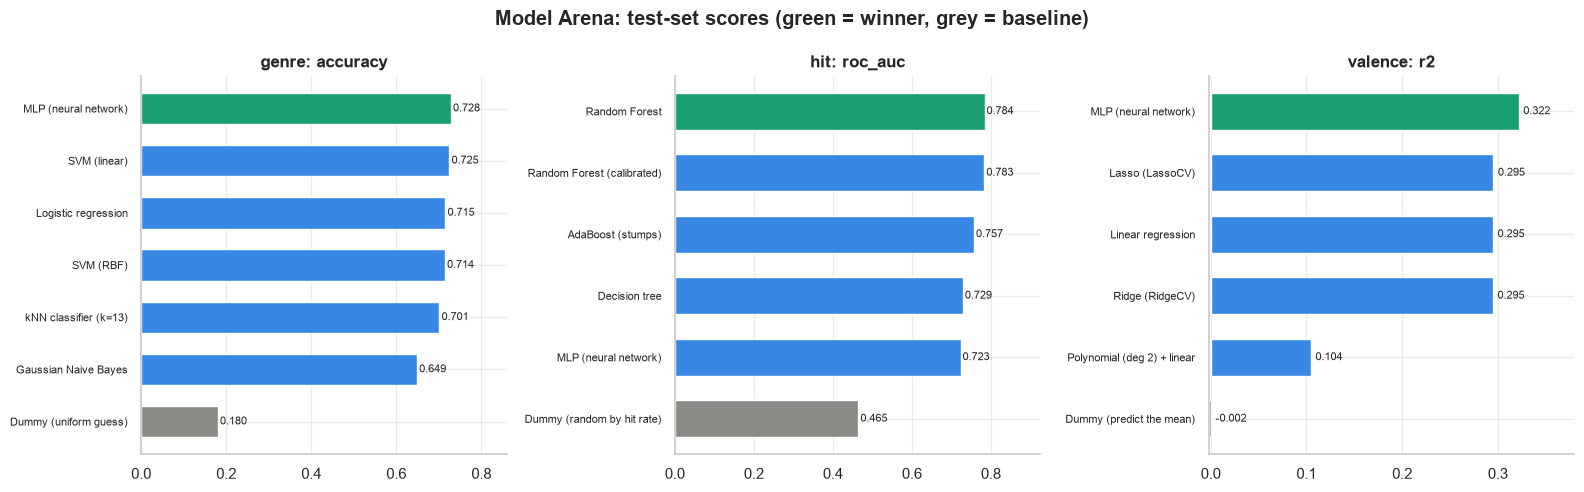

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (task, (cols, key)) in zip(axes, TASKS.items()):
    t = arena_table(task).iloc[::-1]
    colors = ["#8a8a86" if c == "baseline" else ("#199e70" if i == len(t) - 1 else "#3987e5") for i, c in enumerate(t.component)]
    ax.barh(t.model, t[key], color=colors, height=0.6)
    for i, v in enumerate(t[key]): ax.text(max(v, 0) + 0.005, i, f"{v:.3f}", va="center", fontsize=8)
    ax.set_title(f"{task}: {key}"); ax.tick_params(axis="y", labelsize=8); ax.set_xlim(min(0, t[key].min()), t[key].max() * 1.18)
plt.suptitle("Model Arena: test-set scores (green = winner, grey = baseline)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "arena_leaderboard.png", dpi=120); plt.show()

## 7. Is the winner really better? Bootstrap 95% confidence intervals
For the top 3 models of each task (the calibrated forest is left out: calibration does not change how it ranks songs, so it would be a copy of the forest), we resample the 854 test songs with replacement 1,000 times and recompute the main metric each time. We also bootstrap the **difference** between the winner and the runner-up on the same resamples (a paired comparison): if its interval includes 0, the win could be luck.

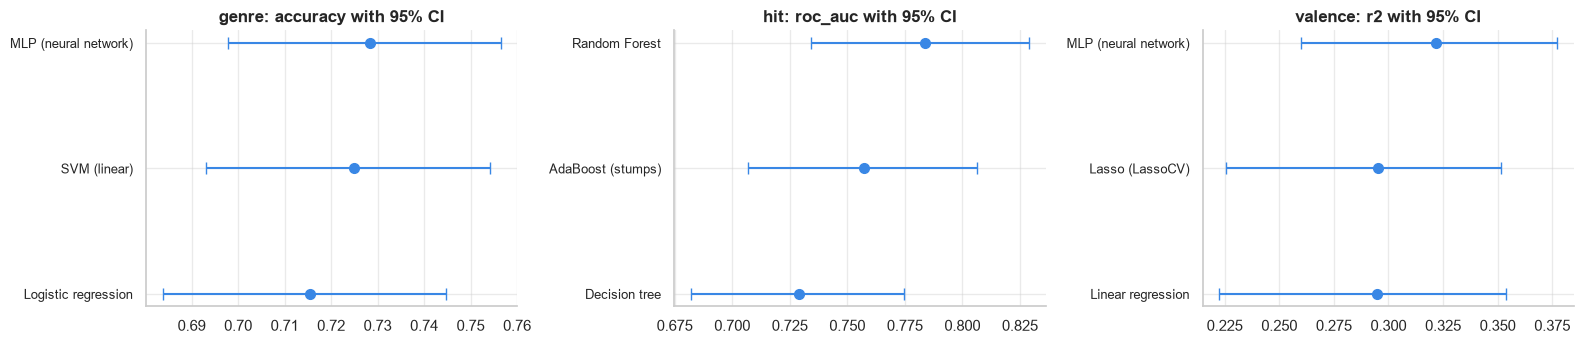

,task,metric,model,test score,95% CI low,95% CI high
0,genre,accuracy,MLP (neural network),0.728,0.698,0.756
1,genre,accuracy,SVM (linear),0.725,0.693,0.754
2,genre,accuracy,Logistic regression,0.715,0.684,0.745
3,hit,roc_auc,Random Forest,0.784,0.734,0.829
4,hit,roc_auc,AdaBoost (stumps),0.757,0.707,0.806
5,hit,roc_auc,Decision tree,0.729,0.682,0.775
6,valence,r2,MLP (neural network),0.322,0.260,0.377
7,valence,r2,Lasso (LassoCV),0.295,0.226,0.352
8,valence,r2,Linear regression,0.295,0.223,0.354


,task,winner,runner-up,mean difference,95% CI of difference,clearly better?
0,genre,MLP (neural network),SVM (linear),0.004,"[-0.021, +0.027]",no (could be luck)
1,hit,Random Forest,AdaBoost (stumps),0.026,"[-0.002, +0.060]",no (could be luck)
2,valence,MLP (neural network),Lasso (LassoCV),0.027,"[-0.023, +0.078]",no (could be luck)


In [13]:
METRIC = {"genre": ("accuracy", lambda yt, yp: accuracy_score(yt, yp), False),
          "hit": ("roc_auc", lambda yt, ys: roc_auc_score(yt, ys), True),
          "valence": ("r2", lambda yt, yp: r2_score(yt, yp), False)}
rng = np.random.default_rng(42)
boot_rows, diff_rows = [], []
for task, (mname, fn, use_score) in METRIC.items():
    preds = evaluate.load_predictions(task)
    t = arena_table(task); t = t[t.component != "baseline"]
    # the calibrated forest ranks songs exactly like the forest itself, so it is skipped here
    top3 = [m for m in t.model if m in preds.columns and "(calibrated)" not in m][:3]
    y = preds["_true"].values
    if task == "hit": y = y.astype(int)
    cols = {m: preds[f"{m} [score]" if use_score else m].values for m in top3}
    idx = rng.integers(0, len(y), (1000, len(y)))
    stats = {m: np.array([fn(y[i], cols[m][i]) for i in idx]) for m in top3}
    for m in top3:
        boot_rows.append({"task": task, "metric": mname, "model": m, "test score": fn(y, cols[m]),
                          "95% CI low": np.quantile(stats[m], .025), "95% CI high": np.quantile(stats[m], .975)})
    d = stats[top3[0]] - stats[top3[1]]
    diff_rows.append({"task": task, "winner": top3[0], "runner-up": top3[1], "mean difference": d.mean(),
                      "95% CI of difference": f"[{np.quantile(d, .025):+.3f}, {np.quantile(d, .975):+.3f}]",
                      "clearly better?": "yes" if np.quantile(d, .025) > 0 else "no (could be luck)"})
boot = pd.DataFrame(boot_rows)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, task in zip(axes, METRIC):
    b = boot[boot.task == task].iloc[::-1]
    ax.errorbar(b["test score"], range(len(b)), xerr=[b["test score"] - b["95% CI low"], b["95% CI high"] - b["test score"]],
                fmt="o", color="#3987e5", capsize=4, ms=7)
    ax.set_yticks(range(len(b)), b.model, fontsize=9); ax.set_title(f"{task}: {METRIC[task][0]} with 95% CI")
plt.tight_layout(); plt.savefig(FIG / "bootstrap_ci.png", dpi=120); plt.show()
display(boot.round(3)); pd.DataFrame(diff_rows).round(3)

This shows that **none of the three winners is clearly better than its runner-up**: the 95% intervals overlap heavily, and every winner-minus-runner-up interval includes 0. For genre the MLP's lead over the linear SVM is only +0.4 points (interval −2.1 to +2.7); for valence the MLP's +0.027 R² over Lasso could be luck; for hit the forest's +0.026 AUC over AdaBoost is the closest to significant (interval −0.002 to +0.060) but still includes 0. With 854 test songs, gaps of 1–3 points are within the noise. Honest conclusion: **several models are equally good**; what clearly matters is model *type* vs the baselines and vs Naive Bayes / the polynomial model.

### Robustness: removing near-duplicate test songs
P1 found 13 test songs whose audio features are identical to a training song (the same recording under a slightly different title). If those twins inflated the scores, removing them from the test set would make scores drop noticeably.

In [14]:
songs_all, _ = data.load_all_songs()
sound_key = lambda d: d[data.AUDIO_FEATURES].round(8).astype(str).agg("|".join, axis=1)
train_keys = set(sound_key(songs_all[songs_all.split == "train"]))
test_songs = songs_all[songs_all.split == "test"]
twin_ids = test_songs.index[sound_key(test_songs).isin(train_keys)]
print(f"Test songs with an identical training twin: {len(twin_ids)}")
rob = []
for task, (mname, fn, use_score) in METRIC.items():
    preds = evaluate.load_predictions(task)
    keep = ~preds.index.isin(twin_ids)
    y = preds["_true"].values.astype(int) if task == "hit" else preds["_true"].values
    for m in [c for c in preds.columns if c != "_true" and not c.endswith("[score]")]:
        col = preds[f"{m} [score]"].values if use_score else preds[m].values
        full, reduced = fn(y, col), fn(y[keep], col[keep])
        rob.append({"task": task, "metric": mname, "model": m, "all 854 test songs": full,
                    "without the twins": reduced, "change": reduced - full})
rob = pd.DataFrame(rob)
print("Largest absolute change in any score: %.4f" % rob["change"].abs().max())
rob.round(4)

Test songs with an identical training twin: 13
Largest absolute change in any score: 0.0065


,task,metric,model,all 854 test songs,without the twins,change
0,genre,accuracy,Logistic regression,0.716,0.719,3.900e-03
1,genre,accuracy,Gaussian Naive Bayes,0.649,0.652,2.900e-03
2,genre,accuracy,kNN classifier (k=13),0.701,0.703,1.300e-03
3,genre,accuracy,SVM (linear),0.725,0.729,4.100e-03
4,genre,accuracy,SVM (RBF),0.714,0.718,3.900e-03
5,genre,accuracy,MLP (neural network),0.728,0.731,2.900e-03
6,hit,roc_auc,Decision tree,0.729,0.732,2.800e-03
7,hit,roc_auc,Random Forest,0.784,0.784,6.000e-04
8,hit,roc_auc,AdaBoost (stumps),0.757,0.756,-1.100e-03
9,hit,roc_auc,Random Forest (calibrated),0.783,0.784,6.000e-04


This shows the 13 near-duplicate test songs **do not inflate the results**: removing them changes every model's score by at most 0.65 percentage points, and for genre the accuracies even go *up* slightly. The leaderboard order and every conclusion stay the same.

## 8. Ablation studies
**(a) With vs without PCA.** The best genre model family (linear SVM, C = 1, from P4) trained on: all 26 features; P1's **7 PCA components** (90% of the audio-feature variance); only the **first 2 components** (the Song Map).
**(b) With vs without the mood cluster.** Add P7's k-means mood (4 one-hot columns) as extra features, for the genre model and for the hit model (P5's Random Forest settings). Note: the moods were found on all songs (clustering uses no labels), so test songs' features slightly shaped the clusters; this is a tiny, label-free effect, and the mood turns out not to help anyway.
Decisions are based on 5-fold CV on the training set; test scores are shown for information.

In [15]:
pca = joblib.load(data.ROOT / "models" / "p1_song_map" / "pca.joblib")
n90 = json.loads((data.ROOT / "models" / "p1_song_map" / "song_map_info.json").read_text())["n_components_90"]
A = data.AUDIO_FEATURES
def pcs(X, n): return pd.DataFrame(pca.transform(X[A])[:, :n], index=X.index, columns=[f"PC{i+1}" for i in range(n)])
moods = pd.read_csv(data.ROOT / "models" / "p7_moods" / "moods.csv", index_col=0)["mood"]
mood_dummies = pd.get_dummies(moods, prefix="mood").astype(float)
def with_mood(X): return pd.concat([X, mood_dummies.loc[X.index]], axis=1)

variants = {
    "all 26 features": (X_train, X_test),
    f"{n90} PCA components (90% variance)": (pcs(X_train, n90), pcs(X_test, n90)),
    "2 PCA components (Song Map)": (pcs(X_train, 2), pcs(X_test, 2)),
    "all 26 features + mood cluster": (with_mood(X_train), with_mood(X_test)),
}
abl = []
for name, (Xa_, Xt_) in variants.items():
    svm = SVC(kernel="linear", C=1)
    cvs = cross_val_score(svm, Xa_, y_train["genre"], cv=cv).mean()
    acc = svm.fit(Xa_, y_train["genre"]).score(Xt_, y_test["genre"])
    abl.append({"task": "genre (linear SVM)", "inputs": name, "CV accuracy": cvs, "test accuracy": acc})
genre_abl = pd.DataFrame(abl)

rf = lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced_subsample", random_state=42, n_jobs=-1)
hit_abl = []
for name in ["all 26 features", "all 26 features + mood cluster"]:
    Xa_, Xt_ = variants[name]
    cvs = cross_val_score(rf(), Xa_, y_train["hit"], cv=cv, scoring="roc_auc").mean()
    auc = roc_auc_score(y_test["hit"], rf().fit(Xa_, y_train["hit"]).predict_proba(Xt_)[:, 1])
    hit_abl.append({"task": "hit (Random Forest)", "inputs": name, "CV ROC-AUC": cvs, "test ROC-AUC": auc})
display(genre_abl.round(3)); pd.DataFrame(hit_abl).round(3)

,task,inputs,CV accuracy,test accuracy
0,genre (linear SVM),all 26 features,0.720,0.725
1,genre (linear SVM),7 PCA components (90% variance),0.676,0.678
2,genre (linear SVM),2 PCA components (Song Map),0.538,0.563
3,genre (linear SVM),all 26 features + mood cluster,0.724,0.717


,task,inputs,CV ROC-AUC,test ROC-AUC
0,hit (Random Forest),all 26 features,0.790,0.784
1,hit (Random Forest),all 26 features + mood cluster,0.791,0.774


This shows:
- **PCA hurts here.** Using P1's 7 components (90% of the audio variance) drops genre accuracy from 72.0% to 67.6% (CV), and the 2-component Song Map only reaches 53.8%. PCA keeps directions of *largest variance*, not the directions that *separate genres*, and it drops the key/time-signature columns; the 10% of variance it throws away still contains genre information. With only 26 features there is no speed or overfitting problem for PCA to solve.
- **The mood cluster adds almost nothing.** Adding P7's mood as 4 extra columns changes genre CV accuracy from 72.0% to 72.4% and hit CV ROC-AUC from 0.790 to 0.791, both within noise (test scores even dip slightly). That makes sense: the mood is computed *from* five features the models already have, so it carries no new information.

## 9. Song Lab: move the sliders, watch the genre guess change
The app's Song Lab starts from a "typical" song (the median of every feature) and lets you move sliders. Here is the demo the brief describes: **raise energy and loudness together** and watch the genre probabilities.

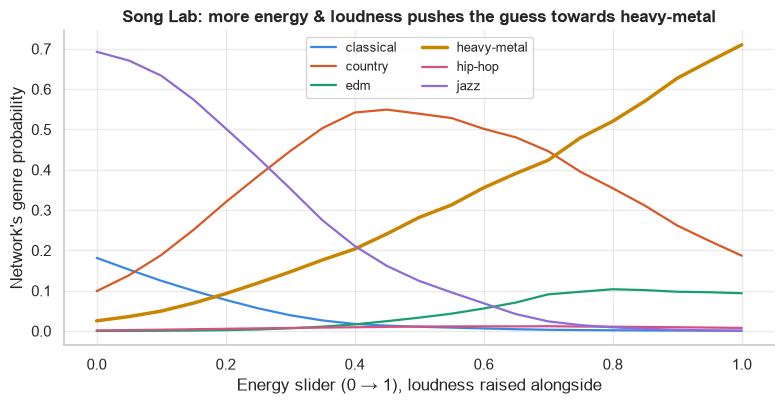

,classical,country,edm,heavy-metal,hip-hop,jazz
0.00,0.18,0.10,0.00,0.03,0.00,0.69
0.25,0.06,0.38,0.00,0.12,0.01,0.43
0.50,0.01,0.54,0.03,0.28,0.01,0.12
0.75,0.00,0.39,0.10,0.48,0.01,0.01
1.00,0.00,0.19,0.09,0.71,0.01,0.00


In [16]:
songs, _ = data.load_all_songs()
raw = songs[feature_names]
base_song = raw.median().to_frame().T            # one-hot columns: median = 0 (the most common case)
steps = np.linspace(0, 1, 21)
rows = []
for s in steps:
    x = base_song.copy()
    x["energy"] = s
    x["loudness"] = raw.loudness.quantile(0.02) + s * (raw.loudness.quantile(0.98) - raw.loudness.quantile(0.02))
    rows.append(mlp_genre.predict_proba(data.scale_raw_features(x))[0])
lab = pd.DataFrame(rows, columns=mlp_genre.classes_, index=steps)
fig, ax = plt.subplots(figsize=(8, 4.2))
for g in GENRES: ax.plot(lab.index, lab[g], lw=2.5 if g == "heavy-metal" else 1.6, color=GENRE_COLORS[g], label=g)
ax.set_xlabel("Energy slider (0 → 1), loudness raised alongside"); ax.set_ylabel("Network's genre probability")
ax.set_title("Song Lab: more energy & loudness pushes the guess towards heavy-metal"); ax.legend(fontsize=9, ncol=2)
plt.tight_layout(); plt.savefig(FIG / "song_lab_demo.png", dpi=120); plt.show()
lab.iloc[[0, 5, 10, 15, 20]].round(2)

This shows the Song Lab demo working: for a typical song with **energy and loudness turned all the way down, the network says jazz (69%) or classical**; in the middle it says **country**; as energy and loudness go up, the **heavy-metal probability climbs from 3% to 71%**. The network has learned the musical intuition that loud, energetic songs are metal and quiet ones are jazz or classical.

## 10. Save the networks (and Song Lab defaults) for the app

In [17]:
joblib.dump({"model": mlp_genre, "name": "MLP (neural network)", "features": feature_names, "params": g_genre.best_params_}, MODELS / "mlp_genre.joblib")
joblib.dump({"model": mlp_hit, "name": "MLP (neural network)", "features": feature_names, "params": g_hit.best_params_}, MODELS / "mlp_hit.joblib")
joblib.dump({"model": mlp_val, "name": "MLP (neural network)", "features": list(Xtr_v.columns), "params": g_val.best_params_}, MODELS / "mlp_valence.joblib")
song_lab = {"base_song": base_song.iloc[0].to_dict(),
            "ranges": {f: [float(raw[f].quantile(0.01)), float(raw[f].quantile(0.99))] for f in data.AUDIO_FEATURES}}
(MODELS / "song_lab.json").write_text(json.dumps(song_lab, indent=2))
pd.DataFrame(diff_rows).to_csv(data.ROOT / "results" / "bootstrap_winners.csv", index=False)
boot.to_csv(data.ROOT / "results" / "bootstrap_ci.csv", index=False)
print("Saved:", sorted(p.name for p in MODELS.iterdir()))

Saved: ['mlp_genre.joblib', 'mlp_hit.joblib', 'mlp_valence.joblib', 'song_lab.json']


## Results summary

**Model Arena winners (test set)**

| Task | Winner | Score | Runner-up | Clearly better? (bootstrap) |
|---|---|---|---|---|
| Genre | MLP (64 ReLU neurons) | accuracy 0.728, macro F1 0.693 | Linear SVM 0.725 | No: difference +0.004, 95% CI [−0.021, +0.027] |
| Hit | Random Forest | ROC-AUC 0.784 | AdaBoost 0.757 | No: +0.026, CI [−0.002, +0.060] |
| Valence | MLP (32→16 ReLU) | R² 0.322 | Lasso 0.295 | No: +0.027, CI [−0.023, +0.078] |

**Neural network scores:** genre accuracy 0.728 · hit ROC-AUC 0.723 · valence R² 0.322.
**Ablations (genre, linear SVM, CV accuracy):** all features 0.720 · 7 PCA components 0.676 · 2 components 0.538 · + mood 0.724.

**Takeaways**
- The MLP is the most flexible model and tops genre and valence, but only by a hair; the tree ensemble wins hits.
- Bootstrap intervals show the top models are statistically tied: on small tabular data, many good models end up equally good.
- Early stopping is essential: without it, validation loss rises from 0.77 to 3.0 as the network memorises the training songs.
- PCA hurts accuracy here (it keeps variance, not genre information); the mood feature adds nothing new.
- Song Lab: raising energy and loudness moves the network's guess from jazz/classical to country to heavy-metal.

## Questions you may be asked

**1. Why do we need activation functions?**
Without them every layer is a weighted sum, and a weighted sum of weighted sums is still just one weighted sum, so a deep network would collapse into linear regression and could only draw straight boundaries. Non-linear activations like ReLU let the network bend its boundaries to fit curved patterns.

**2. Explain backpropagation in two sentences.**
After a forward pass computes the loss, backpropagation applies the chain rule backwards through the network to get, for every weight, how much the loss would change if that weight changed (its gradient). The optimiser then moves every weight a small step against its gradient, and repeating this over many batches and epochs lowers the loss.

**3. How did you choose the number of hidden neurons?**
By 5-fold cross-validation on the training set: we tried one hidden layer of 16, 32 or 64 neurons and two layers (32→16, 64→32), combined with 4 values of alpha (weight penalty) and 2 learning rates, 40 combinations in total. For genre, one layer of 64 neurons with alpha 0.01 and learning rate 0.01 had the best average macro F1 (0.683), although all settings were within about 2 points of each other.

**4. Why don't neural networks always win on small table-style data like ours?**
Neural networks shine with lots of data and raw, unstructured inputs (images, sound waves, text), where they can learn their own features. Our data is a small table: ~3,400 training songs and 26 already-meaningful features. Simpler models (linear SVM, logistic regression) already capture most of the structure, tree ensembles handle threshold-style rules well, and a network has many weights to fit and can overfit easily (see the loss curve). So it ties with the others for genre and loses to the Random Forest on hits.

**5. How do you know the winning model isn't just lucky?**
We don't fully, and the bootstrap shows that. We resampled the 854 test songs 1,000 times and recomputed every top model's score, giving 95% confidence intervals, and also bootstrapped the winner-minus-runner-up difference on the same resamples. For all three tasks the difference interval includes 0, so the winners are not clearly better than the runners-up. They are clearly better than the baselines and the weakest models, whose intervals don't overlap. All models were tuned only on the training set with cross-validation, so the test set did not bias the choice.